In [15]:
from datetime import datetime, timezone
import hashlib
from importlib.metadata import version
import json

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from src import config
from src.data_loader import load_and_split
from src.experiments import run_oof_experiment
from src.preprocess import build_preprocessor

pd.set_option("display.max_columns", None)

In [16]:
EXPERIMENT_ID: str = "lr_raw_v01"
NUMERIC_SCALING: str = "robust"

print("Eksperimen:", EXPERIMENT_ID)
print("Model: Logistic Regression")
print("Fitur: 23 fitur asli, tanpa feature engineering")
print("Scaling numerik:", NUMERIC_SCALING)
print("Target: 1=default, 0=non-default")
print("Biaya FN:", config.FALSE_NEGATIVE_COST)
print("Biaya FP:", config.FALSE_POSITIVE_COST)

Eksperimen: lr_raw_v01
Model: Logistic Regression
Fitur: 23 fitur asli, tanpa feature engineering
Scaling numerik: robust
Target: 1=default, 0=non-default
Biaya FN: 5.0
Biaya FP: 1.0


In [17]:
split = load_and_split()

X_train = split.X_train.copy()
y_train = split.y_train.copy()

print("Train:", X_train.shape)
print("Target:", y_train.value_counts().sort_index().to_dict())

Train: (24000, 23)
Target: {0: 18691, 1: 5309}


In [18]:
pipeline = Pipeline(
    steps=[
        (
            "preprocess",
            build_preprocessor(
                numeric_scaling=NUMERIC_SCALING,
            ),
        ),
        (
            "model",
            LogisticRegression(
                **config.LR_BASELINE_PARAMS,
            ),
        ),
    ]
)

pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default

In [19]:
result = run_oof_experiment(
    pipeline=pipeline,
    X=X_train,
    y=y_train,
)

display(result.fold_metrics.round(4))

display(
    pd.DataFrame(
        [result.summary]
    ).T.rename(columns={0: "value"})
)

,fold,train_rows,validation_rows,roc_auc,average_precision,seconds
0,1,19200,4800,0.7687,0.5479,0.6270
1,2,19200,4800,0.7702,0.5627,0.6419
2,3,19200,4800,0.7580,0.5317,0.7279
3,4,19200,4800,0.7706,0.5306,0.6236
4,5,19200,4800,0.7767,0.5441,0.5704


,value
train_rows,24000.000000
threshold,0.156750
oof_roc_auc,0.768840
oof_average_precision,0.541975
oof_f1_at_selected_threshold,0.497579
oof_total_cost,13502.000000
oof_cost_per_1000,562.583333
tn,12209.000000
fp,6482.000000
fn,1404.000000


In [20]:
default_count = int((y_train == 1).sum())
non_default_count = int((y_train == 0).sum())

policy_comparison = pd.DataFrame({
    "policy": [
        "All non-default",
        "All high-risk",
        EXPERIMENT_ID,
    ],
    "fn": [
        default_count,
        0,
        result.summary["fn"],
    ],
    "fp": [
        0,
        non_default_count,
        result.summary["fp"],
    ],
})

policy_comparison["total_cost"] = (
    config.FALSE_NEGATIVE_COST * policy_comparison["fn"]
    + config.FALSE_POSITIVE_COST * policy_comparison["fp"]
)

policy_comparison["cost_per_1000"] = (
    policy_comparison["total_cost"] / len(y_train) * 1000
)

display(policy_comparison.round(3))

,policy,fn,fp,total_cost,cost_per_1000
0,All non-default,5309,0,26545.0,1106.042
1,All high-risk,0,18691,18691.0,778.792
2,lr_raw_v01,1404,6482,13502.0,562.583


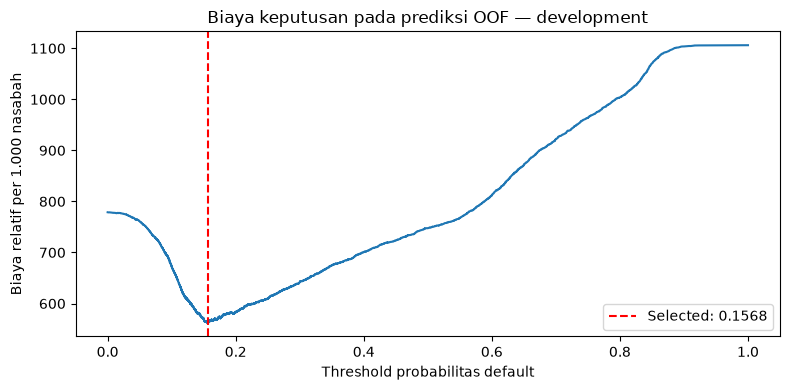

In [21]:
curve = result.threshold_curve

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    curve["threshold"],
    curve["cost_per_1000"],
)

ax.axvline(
    result.summary["threshold"],
    color="red",
    linestyle="--",
    label=f"Selected: {result.summary['threshold']:.4f}",
)

ax.set_xlabel("Threshold probabilitas default")
ax.set_ylabel("Biaya relatif per 1.000 nasabah")
ax.set_title("Biaya keputusan pada prediksi OOF — development")
ax.legend()

plt.tight_layout()
plt.show()

In [22]:
display(result.feature_mapping)

display(
    result.feature_mapping.loc[
        result.feature_mapping["original_feature"].isin(
            ["MARRIAGE", "EDUCATION"]
        )
    ]
)

,encoded_feature,original_feature,category_value,category_label
0,numeric__LIMIT_BAL,LIMIT_BAL,NaN,NaN
1,numeric__AGE,AGE,NaN,NaN
2,numeric__BILL_AMT1,BILL_AMT1,NaN,NaN
3,numeric__BILL_AMT2,BILL_AMT2,NaN,NaN
4,numeric__BILL_AMT3,BILL_AMT3,NaN,NaN
...,...,...,...,...
83,categorical__PAY_6_3,PAY_6,3.0,Code 3
84,categorical__PAY_6_4,PAY_6,4.0,Code 4
85,categorical__PAY_6_5,PAY_6,5.0,Code 5
86,categorical__PAY_6_6,PAY_6,6.0,Code 6


,encoded_feature,original_feature,category_value,category_label
16,categorical__EDUCATION_0,EDUCATION,0.0,Undocumented education code 0
17,categorical__EDUCATION_1,EDUCATION,1.0,Graduate school
18,categorical__EDUCATION_2,EDUCATION,2.0,University
19,categorical__EDUCATION_3,EDUCATION,3.0,High school
20,categorical__EDUCATION_4,EDUCATION,4.0,Others
21,categorical__EDUCATION_5,EDUCATION,5.0,Unknown (code 5)
22,categorical__EDUCATION_6,EDUCATION,6.0,Unknown (code 6)
23,categorical__MARRIAGE_0,MARRIAGE,0.0,Code 0
24,categorical__MARRIAGE_1,MARRIAGE,1.0,Married
25,categorical__MARRIAGE_2,MARRIAGE,2.0,Single


In [23]:
run_id = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S%fZ"
)

run_dir = (
    config.EXPERIMENTS_DIR
    / EXPERIMENT_ID
    / run_id
)

run_dir.mkdir(parents=True, exist_ok=False)

summary_table = pd.DataFrame([{
    "experiment_id": EXPERIMENT_ID,
    "run_id": run_id,
    **result.summary,
}])

tables = {
    "summary": summary_table,
    "fold_metrics": result.fold_metrics,
    "oof_predictions": result.predictions,
    "threshold_curve": result.threshold_curve,
    "feature_mapping": result.feature_mapping,
}

for key, table in tables.items():
    table.to_csv(
        run_dir / config.EXPERIMENT_FILES[key],
        index=False,
    )

metadata = {
    "experiment_id": EXPERIMENT_ID,
    "run_id": run_id,
    "dataset_filename": config.DATA_PATH.name,
    "dataset_sha256": hashlib.sha256(
        config.DATA_PATH.read_bytes()
    ).hexdigest(),
    "feature_columns": list(X_train.columns),
    "numeric_scaling": NUMERIC_SCALING,
    "categorical_encoding": "one_hot",
    "feature_engineering": False,
    "model_parameters": pipeline.named_steps["model"].get_params(),
    "cv_folds": config.CV_FOLDS,
    "cv_random_state": config.CV_RANDOM_STATE,
    "split_random_state": config.RANDOM_STATE,
    "test_size": config.TEST_SIZE,
    "false_negative_cost": config.FALSE_NEGATIVE_COST,
    "false_positive_cost": config.FALSE_POSITIVE_COST,
    "pr_metric_definition": "average_precision",
    "evaluation_scope": "train_oof_development",
    "versions": {
        package: version(package)
        for package in [
            "numpy",
            "pandas",
            "scikit-learn",
        ]
    },
}

with (
    run_dir / config.EXPERIMENT_FILES["metadata"]
).open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, allow_nan=False)

print("Laporan tersimpan:", run_dir)    

Laporan tersimpan: D:\proj-1\reports\experiments\lr_raw_v01\20261004T122756417405Z


In [24]:
from importlib import reload

# Memuat konfigurasi tambahan tanpa melatih ulang model.
reload(config)

default_count = int((y_train == 1).sum())
non_default_count = int((y_train == 0).sum())
sample_count = len(y_train)

sensitivity_rows: list[dict[str, float | int | str]] = []

for ratio in config.COST_RATIOS:
    fp_cost = config.FALSE_POSITIVE_COST
    fn_cost = ratio * fp_cost

    # FN/FP pada setiap threshold sudah tersedia.
    # Hanya fungsi biaya yang berubah untuk skenario ini.
    candidates = result.threshold_curve.copy()

    candidates["scenario_cost"] = (
        fn_cost * candidates["fn"]
        + fp_cost * candidates["fp"]
    )

    best = candidates.sort_values(
        ["scenario_cost", "threshold"]
    ).iloc[0]

    fn = int(best["fn"])
    fp = int(best["fp"])
    tp = default_count - fn
    flagged_count = tp + fp

    all_non_default_cost = fn_cost * default_count
    all_high_risk_cost = fp_cost * non_default_count

    best_simple_cost = min(
        all_non_default_cost,
        all_high_risk_cost,
    )

    best_simple_policy = (
        "All non-default"
        if all_non_default_cost <= all_high_risk_cost
        else "All high-risk"
    )

    sensitivity_rows.append({
        "experiment_id": EXPERIMENT_ID,
        "fn_to_fp_ratio": ratio,
        "threshold": float(best["threshold"]),
        "fn": fn,
        "fp": fp,
        "cost_per_1000": (
            float(best["scenario_cost"]) / sample_count * 1000
        ),
        "best_simple_policy": best_simple_policy,
        "reduction_vs_best_simple_pct": (
            1 - float(best["scenario_cost"]) / best_simple_cost
        ) * 100,
        "recall_pct": tp / default_count * 100,
        "precision_pct": (
            tp / flagged_count * 100
            if flagged_count else 0.0
        ),
        "flagged_pct": flagged_count / sample_count * 100,
    })

cost_sensitivity = pd.DataFrame(sensitivity_rows)

display(cost_sensitivity.round(4))

cost_sensitivity.to_csv(
    run_dir / config.EXPERIMENT_FILES["cost_sensitivity"],
    index=False,
)

metadata["cost_sensitivity"] = {
    "fn_to_fp_ratios": list(config.COST_RATIOS),
    "primary_ratio": (
        config.FALSE_NEGATIVE_COST
        / config.FALSE_POSITIVE_COST
    ),
    "scope": "same_train_oof_probabilities",
}

with (
    run_dir / config.EXPERIMENT_FILES["metadata"]
).open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, allow_nan=False)

,experiment_id,fn_to_fp_ratio,threshold,fn,fp,cost_per_1000,best_simple_policy,reduction_vs_best_simple_pct,recall_pct,precision_pct,flagged_pct
0,lr_raw_v01,2.0,0.3216,2796,1710,304.2500,All non-default,31.2300,47.3347,59.5075,17.5958
1,lr_raw_v01,5.0,0.1568,1404,6482,562.5833,All high-risk,27.7620,73.5543,37.5951,43.2792
2,lr_raw_v01,10.0,0.1109,408,13320,725.0000,All high-risk,6.9071,92.3149,26.8975,75.9208


## Logistic Regression - baseline fitur asli

### Tujuan

Membangun pembanding awal untuk mengukur apakah model yang lebih kompleks memberikan peningkatan kemampuan prediksi dan penurunan penalti keputusan.

### Konfigurasi

- Target: `1=default`, `0=non-default`.
- Menggunakan 23 fitur asli tanpa feature engineering.
- RobustScaler untuk fitur numerik dan One-Hot Encoding untuk kategori.
- Kode kategori dipertahankan secara terpisah.
- Logistic Regression dengan `C=1`, solver `lbfgs`, dan `max_iter=5000`.
- Evaluasi menggunakan 5-fold stratified CV pada 24.000 baris train.
- Preprocessing di-fit ulang dalam setiap training fold.
- Threshold dipilih dari probabilitas OOF dengan meminimalkan `5×FN + FP`.

### Hasil pengembangan

| Ukuran | Hasil |
|---|---:|
| ROC-AUC OOF | 0,768840 |
| Average Precision OOF | 0,541975 |
| F1 pada threshold terpilih | 0,497579 |
| Threshold | 0,156750 |
| FN | 1.404 |
| FP | 6.482 |
| Total penalti keputusan | 13.502 |
| Penalti per 1.000 nasabah | 562,58 |

Pada skenario biaya FN:FP sebesar 5:1, penalti berkurang 27,76% dibandingkan kebijakan sederhana terbaik, yaitu menandai seluruh nasabah sebagai berisiko.

### Interpretasi dan batasan

Baseline ini menangkap 73,55% nasabah default dengan precision 37,60%. Sebanyak 43,28% nasabah ditandai untuk peninjauan.

Biaya merupakan penalti relatif berdasarkan asumsi bisnis, bukan kerugian uang aktual. Threshold dipilih dan dilaporkan pada OOF yang sama, sehingga hasil ini merupakan hasil pengembangan. Test set belum digunakan untuk evaluasi.

### Keputusan berikutnya

Pertahankan eksperimen ini sebagai baseline. Bandingkan dengan model boosting, kemudian uji preprocessing alternatif, feature engineering, dan tuning. Logistic Regression tetap menjadi kandidat model final setelah pengembangan lebih lanjut.

-------------------------------------------------------------------------------------------------

## LightGBM : fitur asli, One-Hot Encoding

Hipotesis:
Hubungan nonlinier dan interaksi antarfitur dapat menurunkan
biaya keputusan dibandingkan Logistic Regression.

Konfigurasi:
- 23 fitur asli
- Numerik tanpa scaling
- One-Hot Encoding untuk kategori
- 5-fold stratified CV yang sama
- Skenario biaya utama FN:FP = 5:1
- Tanpa tuning, feature engineering, atau early stopping

In [25]:
from importlib import reload

from lightgbm import LGBMClassifier

import src.experiments as experiments

reload(config)
reload(experiments)

from src.experiments import (
    run_oof_experiment,
    save_experiment,
    summarize_cost_sensitivity,
)

lr_result = result

lr_sensitivity = summarize_cost_sensitivity(
    lr_result,
    "lr_raw_v01",
)

In [26]:
LGBM_EXPERIMENT_ID: str = "lgbm_raw_v01"

lgbm_preprocessor = build_preprocessor(
    numeric_scaling="none",
).set_output(transform="pandas")

lgbm_pipeline = Pipeline(
    steps=[
        ("preprocess", lgbm_preprocessor),
        (
            "model",
            LGBMClassifier(
                **config.LGBM_BASELINE_PARAMS,
            ),
        ),
    ]
)

lgbm_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default

In [27]:
lgbm_result = run_oof_experiment(
    pipeline=lgbm_pipeline,
    X=X_train,
    y=y_train,
)

display(lgbm_result.fold_metrics.round(4))

display(
    pd.DataFrame(
        [lgbm_result.summary]
    ).T.rename(columns={0: "value"})
)

,fold,train_rows,validation_rows,roc_auc,average_precision,seconds
0,1,19200,4800,0.7858,0.5622,0.5238
1,2,19200,4800,0.7870,0.5735,0.4814
2,3,19200,4800,0.7699,0.5551,0.4906
3,4,19200,4800,0.7870,0.5547,0.4305
4,5,19200,4800,0.7893,0.5587,0.4576


,value
train_rows,24000.000000
threshold,0.167381
oof_roc_auc,0.783724
oof_average_precision,0.559972
oof_f1_at_selected_threshold,0.507040
oof_total_cost,13205.000000
oof_cost_per_1000,550.208333
tn,12496.000000
fp,6195.000000
fn,1402.000000


In [28]:
comparison = pd.DataFrame([
    {
        "experiment_id": "lr_raw_v01",
        **lr_result.summary,
    },
    {
        "experiment_id": LGBM_EXPERIMENT_ID,
        **lgbm_result.summary,
    },
])

comparison_columns = [
    "experiment_id",
    "oof_roc_auc",
    "oof_average_precision",
    "oof_f1_at_selected_threshold",
    "oof_cost_per_1000",
    "fn",
    "fp",
    "threshold",
    "cv_roc_auc_std",
]

display(
    comparison[comparison_columns]
    .sort_values("oof_cost_per_1000")
    .round(4)
)

,experiment_id,oof_roc_auc,oof_average_precision,oof_f1_at_selected_threshold,oof_cost_per_1000,fn,fp,threshold,cv_roc_auc_std
1,lgbm_raw_v01,0.7837,0.560,0.5070,550.2083,1402,6195,0.1674,0.0079
0,lr_raw_v01,0.7688,0.542,0.4976,562.5833,1404,6482,0.1568,0.0068


In [29]:
lgbm_sensitivity = summarize_cost_sensitivity(
    lgbm_result,
    LGBM_EXPERIMENT_ID,
)

sensitivity_comparison = pd.concat(
    [lr_sensitivity, lgbm_sensitivity],
    ignore_index=True,
)

display(
    sensitivity_comparison
    .sort_values(
        ["fn_to_fp_ratio", "cost_per_1000"]
    )
    .round(4)
)

,experiment_id,fn_to_fp_ratio,threshold,fn,fp,cost_per_1000,best_simple_policy,reduction_vs_best_simple_pct,recall_pct,precision_pct,flagged_pct
3,lgbm_raw_v01,2.0,0.3505,2690,1885,302.7083,All non-default,31.5785,49.3313,58.1483,18.7667
0,lr_raw_v01,2.0,0.3216,2796,1710,304.2500,All non-default,31.2300,47.3347,59.5075,17.5958
4,lgbm_raw_v01,5.0,0.1674,1402,6195,550.2083,All high-risk,29.3510,73.5920,38.6755,42.0917
1,lr_raw_v01,5.0,0.1568,1404,6482,562.5833,All high-risk,27.7620,73.5543,37.5951,43.2792
5,lgbm_raw_v01,10.0,0.0956,486,11621,686.7083,All high-risk,11.8239,90.8457,29.3298,68.5167
2,lr_raw_v01,10.0,0.1109,408,13320,725.0000,All high-risk,6.9071,92.3149,26.8975,75.9208


In [30]:
lgbm_run_dir = save_experiment(
    result=lgbm_result,
    pipeline=lgbm_pipeline,
    experiment_id=LGBM_EXPERIMENT_ID,
    numeric_scaling="none",
)

print("Laporan LightGBM tersimpan:", lgbm_run_dir)

Laporan LightGBM tersimpan: D:\proj-1\reports\experiments\lgbm_raw_v01\20261004T122759374534Z


### Eksperimen 03 — XGBoost pada fitur asli

**Experiment ID:** `xgb_raw_v01`

**Tujuan:** menguji apakah XGBoost memberikan biaya kesalahan lebih rendah daripada Logistic Regression dan LightGBM dengan fitur, pembagian fold, serta aturan evaluasi yang sama.

**Konfigurasi eksperimen:**

- Menggunakan 23 fitur asli; `ID` dan target tidak menjadi input model.
- Fitur numerik diteruskan tanpa scaling.
- Fitur kategorikal menggunakan One-Hot Encoding, termasuk kode kategori yang belum terdokumentasi.
- Preprocessing di-fit hanya pada bagian training di setiap fold.
- Menggunakan 5-fold stratified cross-validation dengan pembagian yang sama seperti baseline sebelumnya.
- Menggunakan 200 pohon, learning rate 0,05, dan kedalaman maksimum 5.
- Belum menggunakan feature engineering, tuning, atau early stopping.

**Evaluasi:**

Metrik utama adalah biaya per 1.000 observasi berdasarkan `5 × FN + 1 × FP`. Threshold dipilih menggunakan prediksi OOF pada data latih.

ROC-AUC, Average Precision, F1, recall, precision, dan persentase observasi yang ditandai berisiko digunakan untuk menjelaskan perbedaan performa dan konsekuensi keputusan. Rasio biaya 2:1 dan 10:1 digunakan sebagai analisis sensitivitas.

Test set tetap dikarantina. Hasil OOF digunakan untuk pengembangan dan belum menjadi estimasi performa akhir.

In [31]:
from importlib import reload

import pandas as pd
from IPython.display import display
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src import config
import src.experiments as experiments

reload(config)
reload(experiments)

from src.experiments import (
    run_oof_experiment,
    save_experiment,
    summarize_cost_sensitivity,
)
from src.preprocess import build_preprocessor

In [32]:
XGB_EXPERIMENT_ID: str = "xgb_raw_v01"
XGB_NUMERIC_SCALING: str = "none"

xgb_preprocessor = build_preprocessor(
    numeric_scaling=XGB_NUMERIC_SCALING,
).set_output(transform="pandas")

xgb_pipeline = Pipeline(
    steps=[
        ("preprocess", xgb_preprocessor),
        (
            "model",
            XGBClassifier(**config.XGB_BASELINE_PARAMS),
        ),
    ]
)

xgb_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default

In [33]:
xgb_result = run_oof_experiment(
    pipeline=xgb_pipeline,
    X=X_train,
    y=y_train,
)

display(xgb_result.fold_metrics.round(4))

display(
    pd.Series(
        xgb_result.summary,
        name="value",
    ).to_frame()
)

,fold,train_rows,validation_rows,roc_auc,average_precision,seconds
0,1,19200,4800,0.7841,0.5606,2.2507
1,2,19200,4800,0.7856,0.5813,1.2107
2,3,19200,4800,0.7707,0.5503,1.3885
3,4,19200,4800,0.7898,0.5572,0.5928
4,5,19200,4800,0.7867,0.5521,0.5979


,value
train_rows,24000.000000
threshold,0.136249
oof_roc_auc,0.783288
oof_average_precision,0.558994
oof_f1_at_selected_threshold,0.480708
oof_total_cost,13192.000000
oof_cost_per_1000,549.666667
tn,10179.000000
fp,8512.000000
fn,936.000000


In [34]:
alignment_columns: list[str] = [
    "source_row_index",
    "fold",
    "y_true",
]

reference_alignment = lr_result.predictions[
    alignment_columns
].reset_index(drop=True)

for experiment_id, experiment_result in (
    ("lgbm_raw_v01", lgbm_result),
    (XGB_EXPERIMENT_ID, xgb_result),
):
    current_alignment = experiment_result.predictions[
        alignment_columns
    ].reset_index(drop=True)

    if not reference_alignment.equals(current_alignment):
        raise ValueError(
            f"{experiment_id}: baris, label, atau pembagian fold "
            "berbeda dari baseline LR. Periksa sebelum membandingkan."
        )

comparison_columns: list[str] = [
    "experiment_id",
    "oof_roc_auc",
    "oof_average_precision",
    "oof_f1_at_selected_threshold",
    "oof_cost_per_1000",
    "fn",
    "fp",
    "threshold",
    "cv_roc_auc_std",
]

baseline_comparison = pd.DataFrame(
    [
        {
            "experiment_id": "lr_raw_v01",
            **lr_result.summary,
        },
        {
            "experiment_id": "lgbm_raw_v01",
            **lgbm_result.summary,
        },
        {
            "experiment_id": XGB_EXPERIMENT_ID,
            **xgb_result.summary,
        },
    ]
)

baseline_comparison = (
    baseline_comparison[comparison_columns]
    .sort_values(
        by="oof_cost_per_1000",
        ascending=True,
    )
    .reset_index(drop=True)
)

display(baseline_comparison.round(4))

,experiment_id,oof_roc_auc,oof_average_precision,oof_f1_at_selected_threshold,oof_cost_per_1000,fn,fp,threshold,cv_roc_auc_std
0,xgb_raw_v01,0.7833,0.559,0.4807,549.6667,936,8512,0.1362,0.0074
1,lgbm_raw_v01,0.7837,0.560,0.5070,550.2083,1402,6195,0.1674,0.0079
2,lr_raw_v01,0.7688,0.542,0.4976,562.5833,1404,6482,0.1568,0.0068


In [35]:
baseline_sensitivity = pd.concat(
    [
        summarize_cost_sensitivity(
            result=lr_result,
            experiment_id="lr_raw_v01",
        ),
        summarize_cost_sensitivity(
            result=lgbm_result,
            experiment_id="lgbm_raw_v01",
        ),
        summarize_cost_sensitivity(
            result=xgb_result,
            experiment_id=XGB_EXPERIMENT_ID,
        ),
    ],
    ignore_index=True,
)

baseline_sensitivity = (
    baseline_sensitivity
    .sort_values(
        by=["fn_to_fp_ratio", "cost_per_1000"],
        ascending=True,
    )
    .reset_index(drop=True)
)

display(baseline_sensitivity.round(4))

,experiment_id,fn_to_fp_ratio,threshold,fn,fp,cost_per_1000,best_simple_policy,reduction_vs_best_simple_pct,recall_pct,precision_pct,flagged_pct
0,xgb_raw_v01,2.0,0.3086,2453,2333,301.6250,All non-default,31.8233,53.7954,55.0395,21.6208
1,lgbm_raw_v01,2.0,0.3505,2690,1885,302.7083,All non-default,31.5785,49.3313,58.1483,18.7667
2,lr_raw_v01,2.0,0.3216,2796,1710,304.2500,All non-default,31.2300,47.3347,59.5075,17.5958
3,xgb_raw_v01,5.0,0.1362,936,8512,549.6667,All high-risk,29.4206,82.3696,33.9387,53.6875
4,lgbm_raw_v01,5.0,0.1674,1402,6195,550.2083,All high-risk,29.3510,73.5920,38.6755,42.0917
5,lr_raw_v01,5.0,0.1568,1404,6482,562.5833,All high-risk,27.7620,73.5543,37.5951,43.2792
6,lgbm_raw_v01,10.0,0.0956,486,11621,686.7083,All high-risk,11.8239,90.8457,29.3298,68.5167
7,xgb_raw_v01,10.0,0.0976,455,12068,692.4167,All high-risk,11.0909,91.4296,28.6846,70.5083
8,lr_raw_v01,10.0,0.1109,408,13320,725.0000,All high-risk,6.9071,92.3149,26.8975,75.9208


In [36]:
xgb_run_dir = save_experiment(
    result=xgb_result,
    pipeline=xgb_pipeline,
    experiment_id=XGB_EXPERIMENT_ID,
    numeric_scaling=XGB_NUMERIC_SCALING,
)

print(f"Laporan tersimpan: {xgb_run_dir}")

Laporan tersimpan: D:\proj-1\reports\experiments\xgb_raw_v01\20261004T154814492712Z


## Feature engineering v01 - ringkasan riwayat pembayaran

Hipotesis: tiga ringkasan per nasabah dapat membantu model mengenali
pola nominal nol dan frekuensi keterlambatan.

Fitur asli dan parameter model dipertahankan. Evaluasi menggunakan
fold yang sama, threshold OOF berbasis biaya 5:1, serta sensitivitas
biaya 2:1 dan 10:1. Test set tidak digunakan.

In [39]:
from importlib import import_module, reload

import pandas as pd
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# Reload config sebelum mengimpor modul yang bergantung padanya.
from src import config

reload(config)

print("Config yang digunakan:", config.__file__)

if not hasattr(config, "ENGINEERED_NUMERIC_COLUMNS"):
    raise AttributeError(
        "ENGINEERED_NUMERIC_COLUMNS belum ditemukan. "
        "Periksa file config pada path yang tercetak dan simpan perubahan."
    )

feature_engineering = import_module("src.feature_engineering")
reload(feature_engineering)

preprocess = import_module("src.preprocess")
reload(preprocess)

experiments = import_module("src.experiments")
reload(experiments)

from src.feature_engineering import CreditFeatureEngineer
from src.preprocess import build_preprocessor
from src.experiments import (
    OOFResult,
    run_oof_experiment,
    save_experiment,
    summarize_cost_sensitivity,
)

print("Fitur tambahan:", config.ENGINEERED_NUMERIC_COLUMNS)

Config yang digunakan: D:\proj-1\src\config.py
Fitur tambahan: ('all_amounts_zero', 'zero_payment_months', 'delayed_months_count')


In [40]:
FE_FEATURES: tuple[str, ...] = config.ENGINEERED_NUMERIC_COLUMNS

raw_results: dict[str, OOFResult] = {
    "lr_raw_v01": lr_result,
    "lgbm_raw_v01": lgbm_result,
    "xgb_raw_v01": xgb_result,
}

experiment_specs = [
    (
        "lr_fe_v01",
        "lr_raw_v01",
        LogisticRegression(**config.LR_BASELINE_PARAMS),
        "robust",
    ),
    (
        "lgbm_fe_v01",
        "lgbm_raw_v01",
        LGBMClassifier(**config.LGBM_BASELINE_PARAMS),
        "none",
    ),
    (
        "xgb_fe_v01",
        "xgb_raw_v01",
        XGBClassifier(**config.XGB_BASELINE_PARAMS),
        "none",
    ),
]

fe_results: dict[str, OOFResult] = {}

alignment_columns = [
    "source_row_index",
    "fold",
    "y_true",
]

for experiment_id, raw_id, estimator, scaling in experiment_specs:
    print(f"Menjalankan {experiment_id}...")

    pipeline = Pipeline(
        steps=[
            (
                "feature_engineering",
                CreditFeatureEngineer(features=FE_FEATURES),
            ),
            (
                "preprocess",
                build_preprocessor(
                    numeric_scaling=scaling,
                    additional_numeric_columns=FE_FEATURES,
                ).set_output(transform="pandas"),
            ),
            ("model", estimator),
        ]
    )

    experiment_result = run_oof_experiment(
        pipeline=pipeline,
        X=X_train,
        y=y_train,
    )

    reference = raw_results[raw_id].predictions[
        alignment_columns
    ].reset_index(drop=True)

    current = experiment_result.predictions[
        alignment_columns
    ].reset_index(drop=True)

    if not reference.equals(current):
        raise ValueError(
            f"{experiment_id}: baris atau fold berbeda dari baseline."
        )

    fe_results[experiment_id] = experiment_result

    run_dir = save_experiment(
        result=experiment_result,
        pipeline=pipeline,
        experiment_id=experiment_id,
        numeric_scaling=scaling,
    )

    print(f"Laporan tersimpan: {run_dir}")

Menjalankan lr_fe_v01...
Laporan tersimpan: D:\proj-1\reports\experiments\lr_fe_v01\20261005T072156566068Z
Menjalankan lgbm_fe_v01...
Laporan tersimpan: D:\proj-1\reports\experiments\lgbm_fe_v01\20261005T072200854363Z
Menjalankan xgb_fe_v01...
Laporan tersimpan: D:\proj-1\reports\experiments\xgb_fe_v01\20261005T072203348215Z


In [41]:
all_results: dict[str, OOFResult] = {
    **raw_results,
    **fe_results,
}

comparison_columns = [
    "experiment_id",
    "oof_roc_auc",
    "oof_average_precision",
    "oof_f1_at_selected_threshold",
    "oof_cost_per_1000",
    "fn",
    "fp",
    "threshold",
]

fe_comparison = pd.DataFrame(
    [
        {
            "experiment_id": experiment_id,
            **experiment_result.summary,
        }
        for experiment_id, experiment_result in all_results.items()
    ]
)

display(
    fe_comparison[comparison_columns]
    .sort_values("oof_cost_per_1000")
    .reset_index(drop=True)
    .round(4)
)

,experiment_id,oof_roc_auc,oof_average_precision,oof_f1_at_selected_threshold,oof_cost_per_1000,fn,fp,threshold
0,lgbm_fe_v01,0.7834,0.5617,0.4977,547.0000,1218,7038,0.1543
1,xgb_fe_v01,0.7835,0.5595,0.5195,549.0833,1561,5373,0.1858
2,xgb_raw_v01,0.7833,0.5590,0.4807,549.6667,936,8512,0.1362
3,lgbm_raw_v01,0.7837,0.5600,0.5070,550.2083,1402,6195,0.1674
4,lr_fe_v01,0.7753,0.5489,0.5032,553.5417,1383,6370,0.1558
5,lr_raw_v01,0.7688,0.5420,0.4976,562.5833,1404,6482,0.1568


In [42]:
fe_effect_rows: list[dict[str, str | float | int]] = []

for fe_id, raw_id, _, _ in experiment_specs:
    raw_summary = raw_results[raw_id].summary
    fe_summary = fe_results[fe_id].summary

    raw_cost = raw_summary["oof_cost_per_1000"]
    fe_cost = fe_summary["oof_cost_per_1000"]

    fe_effect_rows.append(
        {
            "experiment_id": fe_id,
            "raw_cost_per_1000": raw_cost,
            "fe_cost_per_1000": fe_cost,
            "cost_reduction_pct": (
                (raw_cost - fe_cost) / raw_cost * 100
            ),
            "roc_auc_change": (
                fe_summary["oof_roc_auc"]
                - raw_summary["oof_roc_auc"]
            ),
            "ap_change": (
                fe_summary["oof_average_precision"]
                - raw_summary["oof_average_precision"]
            ),
            "fn_change": fe_summary["fn"] - raw_summary["fn"],
            "fp_change": fe_summary["fp"] - raw_summary["fp"],
        }
    )

fe_effect = pd.DataFrame(fe_effect_rows)

display(fe_effect.round(4))

,experiment_id,raw_cost_per_1000,fe_cost_per_1000,cost_reduction_pct,roc_auc_change,ap_change,fn_change,fp_change
0,lr_fe_v01,562.5833,553.5417,1.6072,0.0065,0.0069,-21,-112
1,lgbm_fe_v01,550.2083,547.0000,0.5831,-0.0003,0.0017,-184,843
2,xgb_fe_v01,549.6667,549.0833,0.1061,0.0002,0.0005,625,-3139


In [43]:
fe_sensitivity = pd.concat(
    [
        summarize_cost_sensitivity(
            result=experiment_result,
            experiment_id=experiment_id,
        )
        for experiment_id, experiment_result in all_results.items()
    ],
    ignore_index=True,
)

display(
    fe_sensitivity
    .sort_values(
        ["fn_to_fp_ratio", "cost_per_1000"]
    )
    .reset_index(drop=True)
    .round(4)
)

,experiment_id,fn_to_fp_ratio,threshold,fn,fp,cost_per_1000,best_simple_policy,reduction_vs_best_simple_pct,recall_pct,precision_pct,flagged_pct
0,xgb_fe_v01,2.0,0.3849,2843,1552,301.5833,All non-default,31.8327,46.4494,61.3738,16.7417
1,xgb_raw_v01,2.0,0.3086,2453,2333,301.6250,All non-default,31.8233,53.7954,55.0395,21.6208
2,lgbm_fe_v01,2.0,0.3331,2550,2159,302.4583,All non-default,31.6350,51.9684,56.1000,20.4917
3,lgbm_raw_v01,2.0,0.3505,2690,1885,302.7083,All non-default,31.5785,49.3313,58.1483,18.7667
4,lr_fe_v01,2.0,0.2969,2565,2135,302.7083,All non-default,31.5785,51.6858,56.2410,20.3292
5,lr_raw_v01,2.0,0.3216,2796,1710,304.2500,All non-default,31.2300,47.3347,59.5075,17.5958
6,lgbm_fe_v01,5.0,0.1543,1218,7038,547.0000,All high-risk,29.7630,77.0578,36.7598,46.3708
7,xgb_fe_v01,5.0,0.1858,1561,5373,549.0833,All high-risk,29.4955,70.5971,41.0920,38.0042
8,xgb_raw_v01,5.0,0.1362,936,8512,549.6667,All high-risk,29.4206,82.3696,33.9387,53.6875
9,lgbm_raw_v01,5.0,0.1674,1402,6195,550.2083,All high-risk,29.3510,73.5920,38.6755,42.0917


## Feature engineering v02 - agregasi, rasio, dan perubahan riwayat

Tiga kelompok fitur diuji secara terpisah dengan fitur asli tetap
dipertahankan. Parameter model dan fold sama dengan baseline.

Tujuan utama adalah menurunkan biaya OOF pada rasio FN:FP = 5:1.
F1, recall, precision, ROC-AUC, dan Average Precision dilaporkan
untuk menjelaskan perubahan performa. Test set tidak digunakan.

In [44]:
from importlib import import_module, reload

import pandas as pd
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src import config

reload(config)

feature_engineering = import_module("src.feature_engineering")
reload(feature_engineering)

preprocess = import_module("src.preprocess")
reload(preprocess)

experiments = import_module("src.experiments")
reload(experiments)

from src.feature_engineering import CreditFeatureEngineer
from src.preprocess import build_preprocessor
from src.experiments import (
    OOFResult,
    run_oof_experiment,
    save_experiment,
)

print("Kandidat fitur:", config.AVAILABLE_ENGINEERED_COLUMNS)

Kandidat fitur: ('all_amounts_zero', 'zero_payment_months', 'delayed_months_count', 'payment_mean', 'payment_std', 'bill_mean', 'bill_std', 'bill_latest_to_limit', 'payment_mean_to_limit', 'payment_recent_minus_old', 'bill_recent_minus_old', 'max_delay')


In [45]:
feature_groups: dict[str, tuple[str, ...]] = {
    "aggregate": config.FE_AGGREGATE_COLUMNS,
    "relative": config.FE_RELATIVE_COLUMNS,
    "history": config.FE_TEMPORAL_COLUMNS,
}

model_specs = [
    (
        "lr",
        LogisticRegression,
        config.LR_BASELINE_PARAMS,
        "robust",
    ),
    (
        "lgbm",
        LGBMClassifier,
        config.LGBM_BASELINE_PARAMS,
        "none",
    ),
    (
        "xgb",
        XGBClassifier,
        config.XGB_BASELINE_PARAMS,
        "none",
    ),
]

v02_results: dict[str, OOFResult] = {}

alignment_columns = [
    "source_row_index",
    "fold",
    "y_true",
]

for group_name, selected_features in feature_groups.items():
    for model_name, model_class, model_params, scaling in model_specs:
        experiment_id = f"{model_name}_fe_{group_name}_v02"
        raw_id = f"{model_name}_raw_v01"

        print(f"Menjalankan {experiment_id}...")

        pipeline = Pipeline(
            steps=[
                (
                    "feature_engineering",
                    CreditFeatureEngineer(
                        features=selected_features,
                    ),
                ),
                (
                    "preprocess",
                    build_preprocessor(
                        numeric_scaling=scaling,
                        additional_numeric_columns=selected_features,
                    ).set_output(transform="pandas"),
                ),
                (
                    "model",
                    model_class(**model_params),
                ),
            ]
        )

        experiment_result = run_oof_experiment(
            pipeline=pipeline,
            X=X_train,
            y=y_train,
        )

        reference = raw_results[raw_id].predictions[
            alignment_columns
        ].reset_index(drop=True)

        current = experiment_result.predictions[
            alignment_columns
        ].reset_index(drop=True)

        if not reference.equals(current):
            raise ValueError(
                f"{experiment_id}: baris atau fold berbeda "
                "dari baseline."
            )

        v02_results[experiment_id] = experiment_result

        run_dir = save_experiment(
            result=experiment_result,
            pipeline=pipeline,
            experiment_id=experiment_id,
            numeric_scaling=scaling,
        )

        print(f"Laporan tersimpan: {run_dir}")

Menjalankan lr_fe_aggregate_v02...
Laporan tersimpan: D:\proj-1\reports\experiments\lr_fe_aggregate_v02\20261005T074338367002Z
Menjalankan lgbm_fe_aggregate_v02...
Laporan tersimpan: D:\proj-1\reports\experiments\lgbm_fe_aggregate_v02\20261005T074342828329Z
Menjalankan xgb_fe_aggregate_v02...
Laporan tersimpan: D:\proj-1\reports\experiments\xgb_fe_aggregate_v02\20261005T074345572106Z
Menjalankan lr_fe_relative_v02...
Laporan tersimpan: D:\proj-1\reports\experiments\lr_fe_relative_v02\20261005T074348272967Z
Menjalankan lgbm_fe_relative_v02...
Laporan tersimpan: D:\proj-1\reports\experiments\lgbm_fe_relative_v02\20261005T074350464196Z
Menjalankan xgb_fe_relative_v02...
Laporan tersimpan: D:\proj-1\reports\experiments\xgb_fe_relative_v02\20261005T074353112869Z
Menjalankan lr_fe_history_v02...
Laporan tersimpan: D:\proj-1\reports\experiments\lr_fe_history_v02\20261005T074357757490Z
Menjalankan lgbm_fe_history_v02...
Laporan tersimpan: D:\proj-1\reports\experiments\lgbm_fe_history_v02\20261

In [46]:
results_to_compare: dict[str, OOFResult] = {
    **raw_results,
    **fe_results,
    **v02_results,
}

comparison_rows: list[dict[str, str | float | int]] = []

for experiment_id, experiment_result in results_to_compare.items():
    summary = experiment_result.summary

    recall = summary["tp"] / (
        summary["tp"] + summary["fn"]
    )

    flagged = summary["tp"] + summary["fp"]
    precision = (
        summary["tp"] / flagged
        if flagged > 0
        else 0.0
    )

    comparison_rows.append(
        {
            "experiment_id": experiment_id,
            "roc_auc": summary["oof_roc_auc"],
            "average_precision": summary["oof_average_precision"],
            "f1": summary["oof_f1_at_selected_threshold"],
            "recall_pct": recall * 100,
            "precision_pct": precision * 100,
            "cost_per_1000": summary["oof_cost_per_1000"],
            "fn": summary["fn"],
            "fp": summary["fp"],
            "threshold": summary["threshold"],
        }
    )

v02_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("cost_per_1000")
    .reset_index(drop=True)
)

display(v02_comparison.round(4))

,experiment_id,roc_auc,average_precision,f1,recall_pct,precision_pct,cost_per_1000,fn,fp,threshold
0,xgb_fe_aggregate_v02,0.7854,0.5604,0.5136,73.3660,39.5151,543.0000,1414,5962,0.1676
1,xgb_fe_relative_v02,0.7854,0.5596,0.4942,79.0356,35.9462,543.4167,1113,7477,0.1504
2,xgb_fe_history_v02,0.7841,0.5609,0.5103,73.9311,38.9617,544.5417,1384,6149,0.1716
3,lgbm_fe_aggregate_v02,0.7832,0.5570,0.5026,75.8712,37.5711,545.7500,1281,6693,0.1559
4,lgbm_fe_history_v02,0.7835,0.5635,0.4959,77.8678,36.3748,546.0833,1175,7231,0.1500
5,lgbm_fe_relative_v02,0.7839,0.5598,0.4907,79.5253,35.4790,546.3750,1087,7678,0.1446
6,lgbm_fe_v01,0.7834,0.5617,0.4977,77.0578,36.7598,547.0000,1218,7038,0.1543
7,xgb_fe_v01,0.7835,0.5595,0.5195,70.5971,41.0920,549.0833,1561,5373,0.1858
8,xgb_raw_v01,0.7833,0.5590,0.4807,82.3696,33.9387,549.6667,936,8512,0.1362
9,lgbm_raw_v01,0.7837,0.5600,0.5070,73.5920,38.6755,550.2083,1402,6195,0.1674


In [47]:
group_effect_rows: list[dict[str, str | float | int]] = []

for experiment_id, experiment_result in v02_results.items():
    model_name = experiment_id.split("_", maxsplit=1)[0]

    baseline = raw_results[
        f"{model_name}_raw_v01"
    ].summary

    current = experiment_result.summary

    baseline_cost = baseline["oof_cost_per_1000"]
    current_cost = current["oof_cost_per_1000"]

    group_effect_rows.append(
        {
            "experiment_id": experiment_id,
            "cost_reduction_pct": (
                (baseline_cost - current_cost)
                / baseline_cost
                * 100
            ),
            "f1_change": (
                current["oof_f1_at_selected_threshold"]
                - baseline["oof_f1_at_selected_threshold"]
            ),
            "roc_auc_change": (
                current["oof_roc_auc"]
                - baseline["oof_roc_auc"]
            ),
            "ap_change": (
                current["oof_average_precision"]
                - baseline["oof_average_precision"]
            ),
            "fn_change": current["fn"] - baseline["fn"],
            "fp_change": current["fp"] - baseline["fp"],
        }
    )

v02_effect = (
    pd.DataFrame(group_effect_rows)
    .sort_values("cost_reduction_pct", ascending=False)
    .reset_index(drop=True)
)

display(v02_effect.round(4))

,experiment_id,cost_reduction_pct,f1_change,roc_auc_change,ap_change,fn_change,fp_change
0,xgb_fe_aggregate_v02,1.2129,0.0329,0.0021,0.0014,478,-2550
1,xgb_fe_relative_v02,1.1371,0.0135,0.0022,0.0006,177,-1035
2,xgb_fe_history_v02,0.9324,0.0296,0.0008,0.0020,448,-2363
3,lgbm_fe_aggregate_v02,0.8103,-0.0045,-0.0006,-0.0029,-121,498
4,lgbm_fe_history_v02,0.7497,-0.0112,-0.0002,0.0035,-227,1036
5,lgbm_fe_relative_v02,0.6967,-0.0164,0.0002,-0.0002,-315,1483
6,lr_fe_history_v02,0.3851,0.0044,0.0028,0.0006,42,-262
7,lr_fe_relative_v02,-0.0518,-0.0024,0.0007,-0.0011,-36,187
8,lr_fe_aggregate_v02,-0.2000,0.0044,0.0038,0.0020,81,-378


## Eksperimen v03 — Randomized Hyperparameter Search

### Tujuan
Mengukur apakah tuning parameter dapat menurunkan biaya kesalahan
dibanding konfigurasi awal pada representasi fitur yang sama.

### Representasi fitur
- Logistic Regression: fitur asli ditambah tiga fitur FE v01.
- LightGBM dan XGBoost: fitur asli ditambah rata-rata dan standar
  deviasi nominal tagihan serta pembayaran.

Representasi dipilih berdasarkan hasil eksperimen pengembangan sebelumnya.

### Metode
Pencarian menggunakan `ParameterSampler` dari scikit-learn.
XGBoost dan LightGBM masing-masing mendapat anggaran 12 kombinasi
acak, sedangkan Logistic Regression menguji tujuh nilai C.

Konfigurasi awal ikut dievaluasi dan kandidat duplikat dilewati.
Setiap kandidat menggunakan Pipeline serta 5-fold stratified CV
dengan pembagian fold yang sama.

### Kriteria pemilihan
Threshold setiap kandidat dipilih dari probabilitas OOF untuk
meminimalkan `5 × FN + FP`.

Biaya per 1.000 observasi menjadi kriteria utama. ROC-AUC,
Average Precision, F1, FN, dan FP menjadi metrik pendamping.
Tidak digunakan pembobotan kelas, SMOTE, atau early stopping.

### Batas interpretasi
Hasil ini merupakan pencarian kandidat pada data train. Karena
konfigurasi dan threshold dipilih menggunakan hasil OOF, skor
terbaik belum menjadi estimasi performa akhir.

Test set tetap dikarantina. Validasi lanjutan dilakukan sebelum
konfigurasi akhir dibekukan.

In [48]:
from datetime import datetime, timezone
import json
from math import prod
from typing import Any, Literal

import pandas as pd
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.base import BaseEstimator
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import ParameterSampler
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

from src import config
from src.feature_engineering import CreditFeatureEngineer
from src.preprocess import build_preprocessor
from src.experiments import run_oof_experiment, save_experiment

In [49]:
def tune_model(
    *,
    X: pd.DataFrame,
    y: pd.Series,
    model_name: str,
    model_class: type[BaseEstimator],
    base_params: dict[str, Any],
    param_space: dict[str, list[Any]],
    features: tuple[str, ...],
    numeric_scaling: Literal["robust", "none"],
    n_iter: int = 12,
) -> tuple[pd.DataFrame, Pipeline]:
    """Search training OOF cost and return an unfitted best template."""
    if n_iter < 1:
        raise ValueError("n_iter harus minimal 1.")

    if any(not values for values in param_space.values()):
        raise ValueError(
            "Daftar nilai parameter tidak boleh kosong."
        )

    budget = min(
        n_iter,
        prod(len(values) for values in param_space.values()),
    )

    sampled = list(
        ParameterSampler(
            param_space,
            n_iter=budget,
            random_state=config.RANDOM_STATE,
        )
    )

    candidates = [{}] + sampled
    seen = set()
    rows = []
    best_cost = float("inf")
    best_pipeline = None

    for changes in candidates:
        params = {**base_params, **changes}

        signature = tuple(
            sorted(
                (key, repr(value))
                for key, value in params.items()
            )
        )

        if signature in seen:
            continue

        seen.add(signature)
        trial_id = f"{model_name}_tune_v03_{len(rows):03d}"

        steps = []

        if features:
            steps.append(
                (
                    "feature_engineering",
                    CreditFeatureEngineer(features=features),
                )
            )

        steps.extend(
            [
                (
                    "preprocess",
                    build_preprocessor(
                        numeric_scaling=numeric_scaling,
                        additional_numeric_columns=features,
                    ).set_output(transform="pandas"),
                ),
                ("model", model_class(**params)),
            ]
        )

        pipeline = Pipeline(steps)

        print(f"Menjalankan {trial_id}...", flush=True)

        result = run_oof_experiment(
            pipeline=pipeline,
            X=X,
            y=y,
        )

        run_dir = save_experiment(
            result=result,
            pipeline=pipeline,
            experiment_id=trial_id,
            numeric_scaling=numeric_scaling,
        )

        cost = float(
            result.summary["oof_cost_per_1000"]
        )

        rows.append(
            {
                "experiment_id": trial_id,
                **result.summary,
                "parameters": json.dumps(
                    params,
                    sort_keys=True,
                    allow_nan=False,
                ),
                "report_dir": str(run_dir),
            }
        )

        print(
            f"Biaya/1.000={cost:.4f}; "
            f"F1={result.summary['oof_f1_at_selected_threshold']:.4f}",
            flush=True,
        )

        if cost < best_cost:
            best_cost = cost
            best_pipeline = pipeline

    if best_pipeline is None:
        raise RuntimeError(
            "Tidak ada kandidat yang berhasil dievaluasi."
        )

    table = (
        pd.DataFrame(rows)
        .sort_values("oof_cost_per_1000")
        .reset_index(drop=True)
    )

    stamp = datetime.now(timezone.utc).strftime(
        "%Y%m%dT%H%M%S%fZ"
    )

    search_dir = (
        config.EXPERIMENTS_DIR
        / f"{model_name}_search_v03"
        / stamp
    )
    search_dir.mkdir(parents=True, exist_ok=False)

    table.to_csv(
        search_dir / config.EXPERIMENT_FILES["summary"],
        index=False,
    )

    metadata = {
        "evaluation_scope": "train_oof_hyperparameter_search",
        "selection_metric": "oof_cost_per_1000",
        "random_state": config.RANDOM_STATE,
        "cv_folds": config.CV_FOLDS,
        "cv_random_state": config.CV_RANDOM_STATE,
        "false_negative_cost": config.FALSE_NEGATIVE_COST,
        "false_positive_cost": config.FALSE_POSITIVE_COST,
        "base_params": base_params,
        "param_space": param_space,
        "features": list(features),
        "requested_samples": n_iter,
        "candidate_count": len(rows),
        "best_experiment_id": table.iloc[0]["experiment_id"],
    }

    metadata_path = (
        search_dir / config.EXPERIMENT_FILES["metadata"]
    )

    with metadata_path.open("w", encoding="utf-8") as handle:
        json.dump(
            metadata,
            handle,
            indent=2,
            allow_nan=False,
        )

    print(f"Ringkasan pencarian: {search_dir}", flush=True)

    return table, best_pipeline

In [50]:
xgb_param_space = {
    "n_estimators": [200, 400, 800],
    "learning_rate": [0.03, 0.05, 0.08],
    "max_depth": [2, 3, 4, 5],
    "min_child_weight": [1.0, 5.0, 10.0, 20.0],
    "reg_lambda": [1.0, 5.0, 15.0],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

xgb_search, best_xgb_pipeline = tune_model(
    X=X_train,
    y=y_train,
    model_name="xgb_aggregate",
    model_class=XGBClassifier,
    base_params=config.XGB_BASELINE_PARAMS,
    param_space=xgb_param_space,
    features=config.FE_AGGREGATE_COLUMNS,
    numeric_scaling="none",
    n_iter=12,
)

Menjalankan xgb_aggregate_tune_v03_000...
Biaya/1.000=543.0000; F1=0.5136
Menjalankan xgb_aggregate_tune_v03_001...
Biaya/1.000=537.8750; F1=0.5239
Menjalankan xgb_aggregate_tune_v03_002...
Biaya/1.000=542.0833; F1=0.5102
Menjalankan xgb_aggregate_tune_v03_003...
Biaya/1.000=561.6667; F1=0.5055
Menjalankan xgb_aggregate_tune_v03_004...
Biaya/1.000=539.2917; F1=0.5106
Menjalankan xgb_aggregate_tune_v03_005...
Biaya/1.000=544.3750; F1=0.4977
Menjalankan xgb_aggregate_tune_v03_006...
Biaya/1.000=545.5833; F1=0.4948
Menjalankan xgb_aggregate_tune_v03_007...
Biaya/1.000=566.0833; F1=0.4950
Menjalankan xgb_aggregate_tune_v03_008...
Biaya/1.000=543.6250; F1=0.5180
Menjalankan xgb_aggregate_tune_v03_009...
Biaya/1.000=539.4167; F1=0.5020
Menjalankan xgb_aggregate_tune_v03_010...
Biaya/1.000=541.1250; F1=0.4986
Menjalankan xgb_aggregate_tune_v03_011...
Biaya/1.000=543.8750; F1=0.4987
Menjalankan xgb_aggregate_tune_v03_012...
Biaya/1.000=537.7083; F1=0.5052
Ringkasan pencarian: D:\proj-1\reports

In [51]:
lgbm_param_space = {
    "n_estimators": [200, 400, 800],
    "learning_rate": [0.03, 0.05, 0.08],
    "num_leaves": [7, 15, 31, 63],
    "min_child_samples": [20, 50, 100],
    "reg_lambda": [0.0, 1.0, 5.0, 15.0],
    "colsample_bytree": [0.8, 1.0],
}

lgbm_search, best_lgbm_pipeline = tune_model(
    X=X_train,
    y=y_train,
    model_name="lgbm_aggregate",
    model_class=LGBMClassifier,
    base_params=config.LGBM_BASELINE_PARAMS,
    param_space=lgbm_param_space,
    features=config.FE_AGGREGATE_COLUMNS,
    numeric_scaling="none",
    n_iter=12,
)

Menjalankan lgbm_aggregate_tune_v03_000...
Biaya/1.000=545.7500; F1=0.5026
Menjalankan lgbm_aggregate_tune_v03_001...
Biaya/1.000=539.7500; F1=0.5005
Menjalankan lgbm_aggregate_tune_v03_002...
Biaya/1.000=542.1250; F1=0.5112
Menjalankan lgbm_aggregate_tune_v03_003...
Biaya/1.000=540.4583; F1=0.5186
Menjalankan lgbm_aggregate_tune_v03_004...
Biaya/1.000=550.5417; F1=0.4989
Menjalankan lgbm_aggregate_tune_v03_005...
Biaya/1.000=538.8750; F1=0.5227
Menjalankan lgbm_aggregate_tune_v03_006...
Biaya/1.000=544.5833; F1=0.4903
Menjalankan lgbm_aggregate_tune_v03_007...
Biaya/1.000=541.8750; F1=0.5259
Menjalankan lgbm_aggregate_tune_v03_008...
Biaya/1.000=543.4167; F1=0.5114
Menjalankan lgbm_aggregate_tune_v03_009...
Biaya/1.000=543.7083; F1=0.5199
Menjalankan lgbm_aggregate_tune_v03_010...
Biaya/1.000=542.5833; F1=0.5095
Menjalankan lgbm_aggregate_tune_v03_011...
Biaya/1.000=553.0833; F1=0.4960
Menjalankan lgbm_aggregate_tune_v03_012...
Biaya/1.000=549.7500; F1=0.5040
Ringkasan pencarian: D:\p

In [52]:
lr_param_space = {
    "C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
}

lr_search, best_lr_pipeline = tune_model(
    X=X_train,
    y=y_train,
    model_name="lr_flags",
    model_class=LogisticRegression,
    base_params=config.LR_BASELINE_PARAMS,
    param_space=lr_param_space,
    features=config.ENGINEERED_NUMERIC_COLUMNS,
    numeric_scaling="robust",
    n_iter=7,
)

Menjalankan lr_flags_tune_v03_000...
Biaya/1.000=553.5417; F1=0.5032
Menjalankan lr_flags_tune_v03_001...
Biaya/1.000=555.3333; F1=0.5147
Menjalankan lr_flags_tune_v03_002...
Biaya/1.000=554.5833; F1=0.5146
Menjalankan lr_flags_tune_v03_003...
Biaya/1.000=553.2083; F1=0.5068
Menjalankan lr_flags_tune_v03_004...
Biaya/1.000=552.9167; F1=0.5044
Menjalankan lr_flags_tune_v03_005...
Biaya/1.000=553.1250; F1=0.5037
Menjalankan lr_flags_tune_v03_006...
Biaya/1.000=553.8333; F1=0.5027
Ringkasan pencarian: D:\proj-1\reports\experiments\lr_flags_search_v03\20261005T084235469508Z


In [53]:
search_columns = [
    "experiment_id",
    "oof_cost_per_1000",
    "oof_f1_at_selected_threshold",
    "oof_roc_auc",
    "oof_average_precision",
    "fn",
    "fp",
    "threshold",
    "parameters",
]

for name, search in (
    ("XGBoost", xgb_search),
    ("LightGBM", lgbm_search),
    ("Logistic Regression", lr_search),
):
    print(f"\n{name}: lima kandidat terbaik")
    display(search[search_columns].head(5).round(4))


XGBoost: lima kandidat terbaik


,experiment_id,oof_cost_per_1000,oof_f1_at_selected_threshold,oof_roc_auc,oof_average_precision,fn,fp,threshold,parameters
0,xgb_aggregate_tune_v03_012,537.7083,0.5052,0.7837,0.5560,1227,6770,0.1559,"{""colsample_bytree"": 1.0, ""device"": ""cpu"", ""ev..."
1,xgb_aggregate_tune_v03_001,537.8750,0.5239,0.7870,0.5588,1494,5439,0.1787,"{""colsample_bytree"": 1.0, ""device"": ""cpu"", ""ev..."
2,xgb_aggregate_tune_v03_004,539.2917,0.5106,0.7836,0.5522,1328,6303,0.1640,"{""colsample_bytree"": 1.0, ""device"": ""cpu"", ""ev..."
3,xgb_aggregate_tune_v03_009,539.4167,0.5020,0.7843,0.5542,1196,6966,0.1528,"{""colsample_bytree"": 1.0, ""device"": ""cpu"", ""ev..."
4,xgb_aggregate_tune_v03_010,541.1250,0.4986,0.7855,0.5569,1161,7182,0.1498,"{""colsample_bytree"": 0.8, ""device"": ""cpu"", ""ev..."



LightGBM: lima kandidat terbaik


,experiment_id,oof_cost_per_1000,oof_f1_at_selected_threshold,oof_roc_auc,oof_average_precision,fn,fp,threshold,parameters
0,lgbm_aggregate_tune_v03_005,538.8750,0.5227,0.7875,0.5606,1489,5488,0.1776,"{""colsample_bytree"": 0.8, ""deterministic"": tru..."
1,lgbm_aggregate_tune_v03_001,539.7500,0.5005,0.7867,0.5597,1177,7069,0.1511,"{""colsample_bytree"": 0.8, ""deterministic"": tru..."
2,lgbm_aggregate_tune_v03_003,540.4583,0.5186,0.7860,0.5580,1453,5706,0.1755,"{""colsample_bytree"": 1.0, ""deterministic"": tru..."
3,lgbm_aggregate_tune_v03_007,541.8750,0.5259,0.7848,0.5576,1563,5190,0.1826,"{""colsample_bytree"": 1.0, ""deterministic"": tru..."
4,lgbm_aggregate_tune_v03_002,542.1250,0.5112,0.7845,0.5581,1369,6166,0.1645,"{""colsample_bytree"": 1.0, ""deterministic"": tru..."



Logistic Regression: lima kandidat terbaik


,experiment_id,oof_cost_per_1000,oof_f1_at_selected_threshold,oof_roc_auc,oof_average_precision,fn,fp,threshold,parameters
0,lr_flags_tune_v03_004,552.9167,0.5044,0.7756,0.5486,1395,6295,0.1569,"{""C"": 0.3, ""max_iter"": 5000, ""random_state"": 4..."
1,lr_flags_tune_v03_005,553.1250,0.5037,0.7753,0.5482,1386,6345,0.1560,"{""C"": 3.0, ""max_iter"": 5000, ""random_state"": 4..."
2,lr_flags_tune_v03_003,553.2083,0.5068,0.7757,0.5478,1434,6107,0.1592,"{""C"": 0.1, ""max_iter"": 5000, ""random_state"": 4..."
3,lr_flags_tune_v03_000,553.5417,0.5032,0.7753,0.5489,1383,6370,0.1558,"{""C"": 1.0, ""max_iter"": 5000, ""random_state"": 4..."
4,lr_flags_tune_v03_006,553.8333,0.5027,0.7749,0.5472,1379,6397,0.1553,"{""C"": 10.0, ""max_iter"": 5000, ""random_state"": ..."


### Hasil dan keputusan sementara

Kandidat biaya terbaik adalah:
- XGBoost trial 012: biaya 537,7083 per 1.000; F1 0,5052.
- LightGBM trial 005: biaya 538,8750 per 1.000; F1 0,5227.
- Logistic Regression trial 004: biaya 552,9167 per 1.000;
  F1 0,5044.

Dibanding konfigurasi awal pada fitur yang sama, penurunan biaya
sekitar 0,97% untuk XGBoost, 1,26% untuk LightGBM, dan 0,11%
untuk Logistic Regression.

XGBoost trial 012 dan 001 hanya berbeda empat unit penalti pada
24.000 observasi. Trial 012 memiliki FN lebih rendah, sedangkan
trial 001 memiliki FP lebih rendah serta F1 dan ROC-AUC lebih tinggi.
Keduanya dipertahankan sebagai kandidat untuk pemeriksaan lanjutan.

F1 tertinggi dalam pencarian adalah 0,5259 pada LightGBM trial 007,
tetapi kandidat tersebut bukan yang memiliki biaya terendah.

Tuning memberi perbaikan kecil. Hasil ini belum membuktikan
keunggulan yang stabil pada data baru atau penghematan uang nyata.

In [54]:
from importlib import import_module, reload

import pandas as pd
from IPython.display import display
from catboost import CatBoostClassifier
from sklearn.pipeline import Pipeline

from src import config

reload(config)

native_preprocess = import_module("src.native_preprocess")
reload(native_preprocess)

feature_engineering = import_module("src.feature_engineering")
reload(feature_engineering)

preprocess = import_module("src.preprocess")
reload(preprocess)

experiments = import_module("src.experiments")
reload(experiments)

from src.native_preprocess import NativeCategoricalPreprocessor
from src.feature_engineering import CreditFeatureEngineer
from src.experiments import (
    OOFResult,
    run_oof_experiment,
    save_experiment,
)

## Eksperimen v04 — CatBoost dengan Kategorikal Native

### Tujuan
Menguji CatBoost sebagai kandidat tambahan dengan kategori yang
diproses secara native, kemudian membandingkannya dengan kandidat
LR, LightGBM, dan XGBoost.

### Konfigurasi
Digunakan 400 iterasi, learning rate 0,05, kedalaman 5,
dan L2 leaf regularization 5 pada CPU.

Dua representasi diuji dengan konfigurasi model yang sama:
- `cat_raw_v04`: fitur asli.
- `cat_aggregate_v04`: fitur asli ditambah rata-rata dan standar
  deviasi tagihan serta pembayaran.

Kolom kategorikal dikonversi dari kode integer menjadi string.
Fitur numerik diteruskan tanpa scaling. Kode kategori yang belum
terdokumentasi tetap dipertahankan.

### Validasi
Eksperimen menggunakan Pipeline dan 5-fold stratified CV.
Kesamaan baris, label, dan fold diperiksa terhadap baseline sebelumnya.

Threshold dipilih dari prediksi OOF untuk meminimalkan
`5 × FN + FP`. Tidak digunakan early stopping atau pembobotan kelas.
Test set tetap dikarantina.

### Catatan implementasi
Parameter `cat_features` menggunakan tuple untuk menghindari
masalah cloning parameter mutable. Cloning diperiksa sebelum CV.

Hasil eksperimen akan ditambahkan setelah training selesai.

In [56]:
from sklearn.base import clone

CAT_BASELINE_PARAMS = {
    "iterations": 400,
    "learning_rate": 0.05,
    "depth": 5,
    "l2_leaf_reg": 5.0,
    "loss_function": "Logloss",
    "eval_metric": "AUC",
    "cat_features": tuple(config.CATEGORICAL_COLUMNS),
    "random_seed": config.RANDOM_STATE,
    "thread_count": 4,
    "task_type": "CPU",
    "verbose": False,
    "allow_writing_files": False,
}

# Periksa kompatibilitas cloning sebelum menjalankan CV.
probe_model = CatBoostClassifier(**CAT_BASELINE_PARAMS)
probe_clone = clone(probe_model)

print("Cloning CatBoost berhasil.", flush=True)

cat_specs = {
    "cat_raw_v04": (),
    "cat_aggregate_v04": config.FE_AGGREGATE_COLUMNS,
}

cat_results: dict[str, OOFResult] = {}
cat_pipelines: dict[str, Pipeline] = {}

alignment_columns = [
    "source_row_index",
    "fold",
    "y_true",
]

for experiment_id, selected_features in cat_specs.items():
    steps = []

    if selected_features:
        steps.append(
            (
                "feature_engineering",
                CreditFeatureEngineer(
                    features=selected_features,
                ),
            )
        )

    steps.extend(
        [
            (
                "preprocess",
                NativeCategoricalPreprocessor(),
            ),
            (
                "model",
                CatBoostClassifier(**CAT_BASELINE_PARAMS),
            ),
        ]
    )

    pipeline = Pipeline(steps)

    print(f"Menjalankan {experiment_id}...", flush=True)

    result = run_oof_experiment(
        pipeline=pipeline,
        X=X_train,
        y=y_train,
    )

    reference = raw_results["xgb_raw_v01"].predictions[
        alignment_columns
    ].reset_index(drop=True)

    current = result.predictions[
        alignment_columns
    ].reset_index(drop=True)

    if not reference.equals(current):
        raise ValueError(
            f"{experiment_id}: baris atau fold berbeda."
        )

    cat_results[experiment_id] = result
    cat_pipelines[experiment_id] = pipeline

    run_dir = save_experiment(
        result=result,
        pipeline=pipeline,
        experiment_id=experiment_id,
        numeric_scaling="none",
    )

    print(f"Laporan tersimpan: {run_dir}")

Cloning CatBoost berhasil.
Menjalankan cat_raw_v04...
Laporan tersimpan: D:\proj-1\reports\experiments\cat_raw_v04\20261005T091205749651Z
Menjalankan cat_aggregate_v04...
Laporan tersimpan: D:\proj-1\reports\experiments\cat_aggregate_v04\20261005T091457725973Z


In [57]:
cat_comparison = pd.DataFrame(
    [
        {
            "experiment_id": experiment_id,
            **result.summary,
        }
        for experiment_id, result in cat_results.items()
    ]
)

display(
    cat_comparison[
        [
            "experiment_id",
            "oof_cost_per_1000",
            "oof_f1_at_selected_threshold",
            "oof_roc_auc",
            "oof_average_precision",
            "fn",
            "fp",
            "threshold",
        ]
    ]
    .sort_values("oof_cost_per_1000")
    .round(4)
)

,experiment_id,oof_cost_per_1000,oof_f1_at_selected_threshold,oof_roc_auc,oof_average_precision,fn,fp,threshold
1,cat_aggregate_v04,542.7083,0.4921,0.7861,0.5622,1068,7685,0.1403
0,cat_raw_v04,542.9583,0.5261,0.7847,0.5598,1577,5146,0.1828


In [58]:
import json

for name, search, count in (
    ("XGBoost", xgb_search, 2),
    ("LightGBM", lgbm_search, 1),
    ("Logistic Regression", lr_search, 1),
):
    print(f"\n{name}")

    for _, row in search.head(count).iterrows():
        print(row["experiment_id"])
        print(
            json.dumps(
                json.loads(row["parameters"]),
                indent=2,
            )
        )   


XGBoost
xgb_aggregate_tune_v03_012
{
  "colsample_bytree": 1.0,
  "device": "cpu",
  "eval_metric": "logloss",
  "learning_rate": 0.05,
  "max_depth": 3,
  "min_child_weight": 1.0,
  "n_estimators": 800,
  "n_jobs": 4,
  "objective": "binary:logistic",
  "random_state": 42,
  "reg_lambda": 5.0,
  "subsample": 0.8,
  "tree_method": "hist",
  "verbosity": 1
}
xgb_aggregate_tune_v03_001
{
  "colsample_bytree": 1.0,
  "device": "cpu",
  "eval_metric": "logloss",
  "learning_rate": 0.03,
  "max_depth": 5,
  "min_child_weight": 10.0,
  "n_estimators": 400,
  "n_jobs": 4,
  "objective": "binary:logistic",
  "random_state": 42,
  "reg_lambda": 15.0,
  "subsample": 0.8,
  "tree_method": "hist",
  "verbosity": 1
}

LightGBM
lgbm_aggregate_tune_v03_005
{
  "colsample_bytree": 0.8,
  "deterministic": true,
  "force_col_wise": true,
  "learning_rate": 0.03,
  "min_child_samples": 20,
  "n_estimators": 400,
  "n_jobs": 4,
  "num_leaves": 15,
  "objective": "binary",
  "random_state": 42,
  "reg_lam

## Eksperimen v05 - Averaging Probabilitas OOF

Tujuan eksperimen adalah memeriksa apakah kombinasi probabilitas
model dapat menurunkan biaya dibanding model tunggal.

Prediksi OOF kandidat tuning terpilih dan CatBoost digunakan
tanpa training ulang. Baris, label, dan pembagian fold harus sama.

Empat kombinasi dengan bobot sama ditentukan sebelum melihat
hasil averaging. Threshold setiap kombinasi dipilih berdasarkan
biaya `5 × FN + FP`.

Hasil ini merupakan screening pengembangan. Base models telah
dipilih menggunakan hasil CV, sehingga evaluasi ini belum menjadi
estimasi performa akhir ensemble. Test set tetap dikarantina.

In [59]:
from datetime import datetime, timezone
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

from src import config
from src.experiments import build_cost_curve


def load_best_oof(search: pd.DataFrame) -> pd.DataFrame:
    """Load saved OOF predictions of the lowest-cost search candidate."""
    best = search.sort_values(
        "oof_cost_per_1000"
    ).iloc[0]

    run_dir = Path(str(best["report_dir"]))

    metadata_path = (
        run_dir / config.EXPERIMENT_FILES["metadata"]
    )

    with metadata_path.open("r", encoding="utf-8") as handle:
        metadata = json.load(handle)

    current_hash = hashlib.sha256(
        config.DATA_PATH.read_bytes()
    ).hexdigest()

    if metadata["dataset_sha256"] != current_hash:
        raise ValueError(
            "Dataset berbeda dari dataset saat tuning."
        )

    predictions_path = (
        run_dir / config.EXPERIMENT_FILES["oof_predictions"]
    )

    return pd.read_csv(
        predictions_path,
        float_precision="round_trip",
    )


def score_oof_probabilities(
    experiment_id: str,
    y: np.ndarray,
    probabilities: np.ndarray,
) -> dict[str, str | float | int]:
    """Score OOF probabilities at the minimum-cost threshold."""
    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    if probabilities.shape != y.shape:
        raise ValueError(
            "Jumlah probabilitas dan label berbeda."
        )

    if not np.isfinite(probabilities).all():
        raise ValueError(
            "Probabilitas mengandung nilai non-finite."
        )

    if (
        (probabilities < 0) | (probabilities > 1)
    ).any():
        raise ValueError(
            "Probabilitas harus berada dalam rentang 0-1."
        )

    curve = build_cost_curve(y, probabilities)

    best = curve.sort_values(
        ["total_cost", "threshold"],
        ascending=[True, True],
    ).iloc[0]

    threshold = float(best["threshold"])
    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y,
        predictions,
        labels=[0, 1],
    ).ravel()

    return {
        "experiment_id": experiment_id,
        "cost_per_1000": float(best["cost_per_1000"]),
        "total_cost": float(best["total_cost"]),
        "f1": float(
            f1_score(y, predictions, zero_division=0)
        ),
        "roc_auc": float(
            roc_auc_score(y, probabilities)
        ),
        "average_precision": float(
            average_precision_score(y, probabilities)
        ),
        "recall_pct": float(
            recall_score(
                y, predictions, zero_division=0
            ) * 100
        ),
        "precision_pct": float(
            precision_score(
                y, predictions, zero_division=0
            ) * 100
        ),
        "flagged_pct": float(
            predictions.mean() * 100
        ),
        "fn": int(fn),
        "fp": int(fp),
        "threshold": threshold,
    }


# Kandidat biaya terbaik dari pencarian masing-masing model.
sources = {
    "xgb": load_best_oof(xgb_search),
    "lgbm": load_best_oof(lgbm_search),
    "lr": load_best_oof(lr_search),
    "cat_raw": cat_results["cat_raw_v04"].predictions.copy(),
    "cat_aggregate": (
        cat_results["cat_aggregate_v04"].predictions.copy()
    ),
}

alignment_columns = [
    "source_row_index",
    "fold",
    "y_true",
]

reference = sources["xgb"][
    alignment_columns
].reset_index(drop=True)

probability_columns = {}

for name, predictions in sources.items():
    current = predictions[
        alignment_columns
    ].reset_index(drop=True)

    if not reference.equals(current):
        raise ValueError(
            f"{name}: baris, label, atau fold berbeda."
        )

    probability_columns[name] = (
        predictions["probability_default"]
        .to_numpy(dtype=float)
    )

probabilities = pd.DataFrame(probability_columns)
y_oof = reference["y_true"].to_numpy(dtype=int)

# Kombinasi ditetapkan dahulu; setiap anggota berbobot sama.
blend_specs = {
    "blend_xgb_lgbm_v05": ("xgb", "lgbm"),
    "blend_three_catraw_v05": (
        "xgb", "lgbm", "cat_raw",
    ),
    "blend_three_catagg_v05": (
        "xgb", "lgbm", "cat_aggregate",
    ),
    "blend_four_v05": (
        "xgb", "lgbm", "cat_aggregate", "lr",
    ),
}

score_rows = []
prediction_bundle = reference.copy()

# Model tunggal dinilai ulang dengan fungsi yang sama.
for name in probabilities.columns:
    p = probabilities[name].to_numpy()

    prediction_bundle[f"probability_{name}"] = p

    score_rows.append(
        score_oof_probabilities(
            experiment_id=f"single_{name}",
            y=y_oof,
            probabilities=p,
        )
    )

# Averaging probabilitas; tidak ada meta-model yang dilatih.
for experiment_id, members in blend_specs.items():
    p = probabilities[
        list(members)
    ].mean(axis=1).to_numpy()

    prediction_bundle[
        f"probability_{experiment_id}"
    ] = p

    score_rows.append(
        score_oof_probabilities(
            experiment_id=experiment_id,
            y=y_oof,
            probabilities=p,
        )
    )

blend_comparison = (
    pd.DataFrame(score_rows)
    .sort_values("cost_per_1000")
    .reset_index(drop=True)
)

display(blend_comparison.round(4))

# Simpan screening dan probabilitas sumber agar dapat direproduksi.
stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S%fZ"
)

blend_dir = (
    config.EXPERIMENTS_DIR
    / "blend_oof_v05"
    / stamp
)
blend_dir.mkdir(parents=True, exist_ok=False)

blend_comparison.to_csv(
    blend_dir / config.EXPERIMENT_FILES["summary"],
    index=False,
)

prediction_bundle.to_csv(
    blend_dir / config.EXPERIMENT_FILES["oof_predictions"],
    index=False,
)

blend_metadata = {
    "evaluation_scope": "train_oof_blend_development",
    "weighting": "equal",
    "blend_members": {
        name: list(members)
        for name, members in blend_specs.items()
    },
    "search_sources": {
        name: str(
            search.sort_values(
                "oof_cost_per_1000"
            ).iloc[0]["report_dir"]
        )
        for name, search in (
            ("xgb", xgb_search),
            ("lgbm", lgbm_search),
            ("lr", lr_search),
        )
    },
    "catboost_parameters": CAT_BASELINE_PARAMS,
    "dataset_sha256": hashlib.sha256(
        config.DATA_PATH.read_bytes()
    ).hexdigest(),
    "false_negative_cost": config.FALSE_NEGATIVE_COST,
    "false_positive_cost": config.FALSE_POSITIVE_COST,
    "cv_folds": config.CV_FOLDS,
    "cv_random_state": config.CV_RANDOM_STATE,
}

with (
    blend_dir / config.EXPERIMENT_FILES["metadata"]
).open("w", encoding="utf-8") as handle:
    json.dump(
        blend_metadata,
        handle,
        indent=2,
        allow_nan=False,
    )

print(f"Laporan averaging tersimpan: {blend_dir}")

,experiment_id,cost_per_1000,total_cost,f1,roc_auc,average_precision,recall_pct,precision_pct,flagged_pct,fn,fp,threshold
0,blend_four_v05,536.3333,12872.0,0.5099,0.7881,0.5638,75.8147,38.4175,43.6542,1284,6452,0.1577
1,blend_xgb_lgbm_v05,536.4583,12875.0,0.5162,0.7867,0.5600,74.0817,39.6152,41.3667,1376,5995,0.1682
2,blend_three_catraw_v05,536.6250,12879.0,0.5170,0.7877,0.5634,73.8369,39.7808,41.0583,1389,5934,0.1681
3,blend_three_catagg_v05,536.9583,12887.0,0.5154,0.7878,0.5631,74.1948,39.4848,41.5667,1370,6037,0.1659
4,single_xgb,537.7083,12905.0,0.5052,0.7837,0.5560,76.8883,37.6152,45.2167,1227,6770,0.1559
5,single_lgbm,538.8750,12933.0,0.5227,0.7875,0.5606,71.9533,41.0400,38.7833,1489,5488,0.1776
6,single_cat_aggregate,542.7083,13025.0,0.4921,0.7861,0.5622,79.8832,35.5610,49.6917,1068,7685,0.1403
7,single_cat_raw,542.9583,13031.0,0.5261,0.7847,0.5598,70.2957,42.0365,36.9917,1577,5146,0.1828
8,single_lr,552.9167,13270.0,0.5044,0.7756,0.5486,73.7239,38.3387,42.5375,1395,6295,0.1569


Laporan averaging tersimpan: D:\proj-1\reports\experiments\blend_oof_v05\20261005T092357545754Z
